In [1]:
import sys
from pathlib import Path

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.dummy import DummyRegressor
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

import joblib

In [2]:
PROJECT_ROOT = Path.cwd()

if PROJECT_ROOT.name == "notebooks":
    PROJECT_ROOT = PROJECT_ROOT.parent
    
DATA_PATH = PROJECT_ROOT / "data" / "SkyCity Auckland Restaurants & Bars.csv"

df = pd.read_csv(DATA_PATH)

In [3]:
df.head()

,CuisineType,RestaurantID,RestaurantName,Segment,Subregion,GrowthFactor,AOV,MonthlyOrders,InStoreOrders,InStoreRevenue,...,DeliveryCostPerOrder,SD_DeliveryTotalCost,InStoreNetProfit,UberEatsNetProfit,DoorDashNetProfit,SelfDeliveryNetProfit,InStoreShare,UE_share,DD_share,SD_share
0,Burgers,25731,Urban Burgers House,Cafe,North Shore,1.03,43.97,668,197,8662.09,...,3.25,458.25,3682.14,1352.45,752.78,2177.19,0.42,0.45,0.25,0.3
1,Burgers,25123,Urban Burgers Diner,QSR,South Auckland,1.05,40.45,1388,259,10476.55,...,4.72,1600.08,3605.72,1318.61,731.99,3119.38,0.23,0.45,0.25,0.3
2,Burgers,25177,King Burgers Eatery,Cafe,West Auckland,1.04,40.03,1717,524,20975.72,...,3.25,1163.50,7810.95,1555.90,863.42,4172.99,0.44,0.45,0.25,0.3
3,Burgers,25540,Classic Burgers Tavern,QSR,North Shore,1.03,36.28,1083,216,7836.48,...,0.89,231.40,2546.02,-72.25,-40.20,2833.26,0.25,0.45,0.25,0.3
4,Burgers,25258,Lucky Burgers Bistro,Cafe,South Auckland,1.05,34.34,1230,261,8962.74,...,2.66,774.06,3093.09,226.17,125.53,2674.56,0.27,0.45,0.25,0.3


In [4]:
df.shape

(1696, 30)

In [5]:
aliases = {
    "InStoreOrdersCount": "InStoreOrders",
    "UberEatsOrdersCount": "UberEatsOrders",
    "DoorDashOrdersCount": "DoorDashOrders",
    "SelfDeliveryOrdersCount": "SelfDeliveryOrders",
    "DeliveryCostOrder": "DeliveryCostPerOrder",
}

for old_name, new_name in aliases.items():
    if old_name in df.columns and new_name not in df.columns:
        df = df.rename(columns = {old_name: new_name})
        
print("Column names standardized.")

Column names standardized.


In [6]:
profit_columns = [
    "InStoreNetProfit",
    "UberEatsNetProfit",
    "DoorDashNetProfit",
    "SelfDeliveryNetProfit",
]

categorical_features = [
    "CuisineType",
    "Segment",
    "Subregion",
]

numeric_features = [
    "GrowthFactor",
    "AOV",
    "MonthlyOrders",
    "InStoreOrders",
    "UberEatsOrders",
    "DoorDashOrders",
    "SelfDeliveryOrders",
    "COGSRate",
    "OPEXRate",
    "CommissionRate",
    "DeliveryRadiusKM",
    "DeliveryCostPerOrder"
]

feature_columns = categorical_features + numeric_features

required_columns = feature_columns + profit_columns
missing_columns = sorted(set(required_columns) - set(df.columns))

if missing_columns:
    raise ValueError(f"Missing columns: {missing_columns}")

X = df[feature_columns].copy()
y = df[profit_columns].sum(axis=1).rename("TotalNetProfit")

valid_rows = y.notna() & np.isfinite(y)
X = X.loc[valid_rows].copy()
y = y.loc[valid_rows].copy()

print("Feature matrix:", X.shape)
print("Target:", y.shape)
print("Missing target values:", y.isna().sum())

display(X.head())

Feature matrix: (1696, 15)
Target: (1696,)
Missing target values: 0


,CuisineType,Segment,Subregion,GrowthFactor,AOV,MonthlyOrders,InStoreOrders,UberEatsOrders,DoorDashOrders,SelfDeliveryOrders,COGSRate,OPEXRate,CommissionRate,DeliveryRadiusKM,DeliveryCostPerOrder
0,Burgers,Cafe,North Shore,1.03,43.97,668,197,212,118,141,0.208741,0.366172,0.28,11,3.25
1,Burgers,QSR,South Auckland,1.05,40.45,1388,259,508,282,339,0.248217,0.407613,0.28,16,4.72
2,Burgers,Cafe,West Auckland,1.04,40.03,1717,524,537,298,358,0.219688,0.407932,0.30,11,3.25
3,Burgers,QSR,North Shore,1.03,36.28,1083,216,390,217,260,0.237291,0.437815,0.33,3,0.89
4,Burgers,Cafe,South Auckland,1.05,34.34,1230,261,436,242,291,0.221438,0.433457,0.33,9,2.66


In [7]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state= 42
)

print("Training rows:", len(X_train))
print("Testing rows:", len(X_test))

Training rows: 1356
Testing rows: 340


In [8]:
numeric_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

categorical_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy= "most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

preprocessor = ColumnTransformer([
    ("numeric", numeric_pipeline, numeric_features),
    ("categorical", categorical_pipeline, categorical_features)
])

print("preprocessing pipeline created.")

preprocessing pipeline created.


In [9]:
models = {
    "Dummy Baseline": DummyRegressor(strategy="mean"),
    
    "Linear Regression": Pipeline([
        ("preprocessor", preprocessor),
        ("model", LinearRegression()),
    ]),
    
    "Random Forest": Pipeline([
        ("preprocessor", preprocessor),
        ("model", RandomForestRegressor(
            n_estimators= 300,
            min_samples_leaf= 2,
            random_state= 42,
            n_jobs= -1
        )),
    ]),
    
    "Gradient Boosting": Pipeline([
        ("preprocessor", preprocessor),
        ("model", GradientBoostingRegressor(
            n_estimators= 150,
            learning_rate= 0.05,
            max_depth= 2,
            random_state= 42
        )),
    ]),
}

results = []
trained_models = {}

for name, model in models.items():
    model.fit(X_train, y_train)
    predictions = model.predict(X_test)
    
    mae = mean_absolute_error(y_test, predictions)
    rmse = np.sqrt(mean_squared_error(y_test, predictions))
    r2 = r2_score(y_test, predictions)
    
    results.append({
        "Model": name,
        "MAE": mae,
        "RMSE": rmse,
        "R2": r2,
    })
    
    trained_models[name] = model
    
    print(
        f"{name}: MAE={mae:.2f}, "
        f"RMSE = {rmse:.2f}, R2={r2:.4f}"
    )
    
results_df = pd.DataFrame(results).sort_values("MAE")
display(results_df.round(3))

Dummy Baseline: MAE=4485.18, RMSE = 5673.73, R2=-0.0008
Linear Regression: MAE=1301.84, RMSE = 1792.65, R2=0.9001
Random Forest: MAE=867.69, RMSE = 1171.70, R2=0.9573
Gradient Boosting: MAE=1072.16, RMSE = 1381.17, R2=0.9407


,Model,MAE,RMSE,R2
2,Random Forest,867.688,1171.698,0.957
3,Gradient Boosting,1072.157,1381.174,0.941
1,Linear Regression,1301.844,1792.647,0.900
0,Dummy Baseline,4485.182,5673.734,-0.001


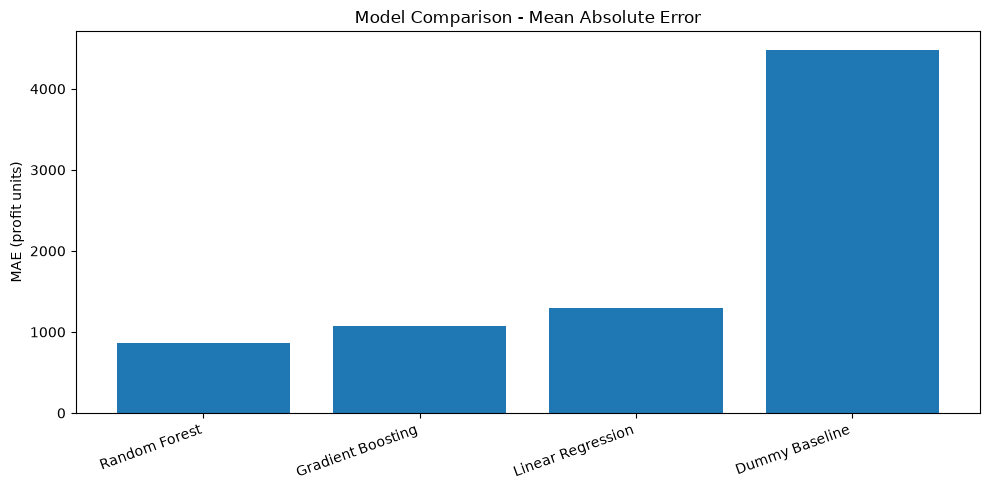

In [10]:
plt.figure(figsize=(10, 5))

plt.bar(results_df["Model"], results_df["MAE"])

plt.title("Model Comparison - Mean Absolute Error")
plt.ylabel("MAE (profit units)")
plt.xticks(rotation=20, ha= "right")
plt.tight_layout()
plt.show()

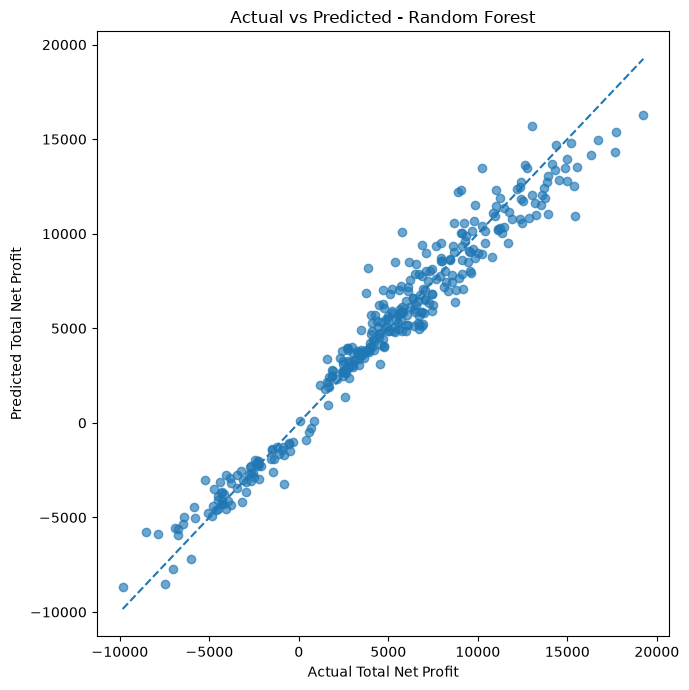

Lowest-MAE model: Random Forest


In [13]:
best_model_name = results_df.iloc[0]["Model"]
best_model = trained_models[best_model_name]

y_pred = best_model.predict(X_test)

plt.figure(figsize=(7,7))

plt.scatter(y_test, y_pred, alpha=0.65)

lower = min(y_test.min(), y_pred.min())
upper = max(y_test.max(), y_pred.max())

plt.plot([lower, upper], [lower, upper], linestyle="--")

plt.xlabel("Actual Total Net Profit")
plt.ylabel("Predicted Total Net Profit")
plt.title(f"Actual vs Predicted - {best_model_name}")
plt.tight_layout()
plt.show()

print("Lowest-MAE model:", best_model_name)

In [17]:
MODEL_DIR = PROJECT_ROOT / "models"
OUTPUT_DIR = PROJECT_ROOT / "outputs" / "reports"

model_path = MODEL_DIR / "restaurant_profit_model.joblib"

joblib.dump({
    "model": best_model,
    "features": feature_columns,
    "target": "TotalNetProfit",
    "model_name": best_model_name,
}, model_path)

results_df.to_csv(
    OUTPUT_DIR / "model_comparison.csv",
    index=False
)

In [27]:
sample = X_test.iloc[[0]]
actual_profit = float(y_test.iloc[0])

predicted_profit = float(best_model.predict(sample)[0])

print("Model:", best_model_name)
print(f"Actual profit :     {actual_profit:,.2f}")
print(f"Predicted profit : {predicted_profit:,.2f}")
print(f"Absolute error: {abs(actual_profit - predicted_profit):,.2f}")

Model: Random Forest
Actual profit :     5,660.20
Predicted profit : 6,016.66
Absolute error: 356.46
